In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path
from typing import Any

import pandas as pd

RUN_METRIC_COLUMNS = ["Pass%", "Step", "PStep", "FStep", "Cost", "PCost", "FCost"]
HARNESS_KEY_MAP = {
    "Step": "average_steps",
    "PStep": "average_steps_passed",
    "FStep": "average_steps_failed",
    "Cost": "average_cost",
    "PCost": "average_cost_passed",
    "FCost": "average_cost_failed",
}

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "results").exists() and (NOTEBOOK_DIR / "harness" / "results").exists():
    NOTEBOOK_DIR = (NOTEBOOK_DIR / "harness").resolve()

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

try:
    import matplotlib.pyplot as plt
    import seaborn as sns
except ImportError as exc:
    plt = None
    sns = None
    PLOT_IMPORT_ERROR = exc
else:
    PLOT_IMPORT_ERROR = None
    sns.set_theme(style="whitegrid", context="talk")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)


def discover_run_dirs(experiment_dir: str | Path) -> list[Path]:
    path = Path(experiment_dir).expanduser().resolve()
    if not path.is_dir():
        raise FileNotFoundError(f"Experiment directory not found: {path}")
    return sorted(child for child in path.iterdir() if child.is_dir())


def _format_experiment_label(experiment_dir: Path, results_root: str | Path | None = None) -> str:
    if results_root is None:
        return experiment_dir.name
    root_path = Path(results_root).expanduser().resolve()
    try:
        return experiment_dir.resolve().relative_to(root_path).as_posix()
    except ValueError:
        return experiment_dir.name


def _to_float(value: Any) -> float:
    if value is None:
        return math.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        return math.nan


def _to_int(value: Any) -> int:
    if value is None:
        return 0
    try:
        return int(float(value))
    except (TypeError, ValueError):
        return 0


def load_run_data(run_dir: str | Path, results_root: str | Path | None = None):
    run_path = Path(run_dir).expanduser().resolve()
    eval_results_path = run_path / "eval_results.json"
    if not eval_results_path.is_file():
        raise FileNotFoundError(f"Missing eval_results.json: {eval_results_path}")

    with eval_results_path.open("r") as f:
        payload = json.load(f)

    if not isinstance(payload, dict):
        raise ValueError(f"Expected JSON object in {eval_results_path}")
    if len(payload) != 1:
        raise ValueError(
            f"Expected exactly one agent entry in {eval_results_path}, found {len(payload)}"
        )

    agent_name, agent_payload = next(iter(payload.items()))
    if not isinstance(agent_payload, dict):
        raise ValueError(f"Expected object payload for agent {agent_name!r} in {eval_results_path}")

    instance_results = agent_payload.get("instance_results")
    instance_metrics = agent_payload.get("instance_metrics")
    harness_metrics = agent_payload.get("harness_metrics", {})

    if not isinstance(instance_results, dict):
        raise ValueError(f"Invalid instance_results for run {run_path}")
    if instance_metrics is None:
        instance_metrics = {}
    if not isinstance(instance_metrics, dict):
        raise ValueError(f"Invalid instance_metrics for run {run_path}")
    if harness_metrics is None:
        harness_metrics = {}
    if not isinstance(harness_metrics, dict):
        raise ValueError(f"Invalid harness_metrics for run {run_path}")

    normalized_results = {str(instance_id): bool(passed) for instance_id, passed in instance_results.items()}
    passed_instances = sum(normalized_results.values())
    total_instances = len(normalized_results)
    failed_instances = total_instances - passed_instances

    warnings = []
    run_row = {
        "experiment": _format_experiment_label(run_path.parent, results_root=results_root),
        "experiment_dir": str(run_path.parent),
        "run_name": run_path.name,
        "run_dir": str(run_path),
        "agent_name": str(agent_name),
        "total_instances": total_instances,
        "passed_instances": passed_instances,
        "failed_instances": failed_instances,
        "Pass%": (100.0 * passed_instances / total_instances) if total_instances else math.nan,
    }

    for metric_name, harness_key in HARNESS_KEY_MAP.items():
        run_row[metric_name] = _to_float(harness_metrics.get(harness_key))
        if harness_key not in harness_metrics:
            warnings.append(
                f"Run {run_path} is missing harness_metrics.{harness_key}; {metric_name} will be NaN"
            )

    instance_rows = []
    if not instance_metrics:
        warnings.append(f"Run {run_path} is missing instance_metrics; instance-level plots will skip this run")
    else:
        missing_metric_ids = sorted(set(normalized_results) - set(instance_metrics))
        if missing_metric_ids:
            warnings.append(
                f"Run {run_path} is missing instance_metrics for {len(missing_metric_ids)} instance(s)"
            )

        for instance_id, passed in normalized_results.items():
            item = instance_metrics.get(instance_id)
            if not isinstance(item, dict):
                continue
            instance_rows.append(
                {
                    "experiment": run_row["experiment"],
                    "experiment_dir": run_row["experiment_dir"],
                    "run_name": run_row["run_name"],
                    "run_dir": run_row["run_dir"],
                    "agent_name": run_row["agent_name"],
                    "instance_id": instance_id,
                    "passed": bool(item.get("passed", passed)),
                    "steps": _to_int(item.get("steps")),
                    "cost": _to_float(item.get("cost")),
                    "input_tokens": _to_int(item.get("input_tokens")),
                    "output_tokens": _to_int(item.get("output_tokens")),
                    "cache_tokens": _to_int(item.get("cache_tokens")),
                    "has_traj_cost": bool(item.get("has_traj_cost", False)),
                }
            )

    return run_row, instance_rows, warnings


def build_experiment_frames(experiment_dirs: list[str | Path], results_root: str | Path | None = None):
    warnings = []
    summary_rows = []
    run_rows = []
    instance_rows = []

    for experiment_dir in experiment_dirs:
        experiment_path = Path(experiment_dir).expanduser().resolve()
        experiment_label = _format_experiment_label(experiment_path, results_root=results_root)

        try:
            run_dirs = discover_run_dirs(experiment_path)
        except FileNotFoundError as exc:
            warnings.append(str(exc))
            summary_row = {
                "experiment": experiment_label,
                "experiment_dir": str(experiment_path),
                "valid_runs": 0,
                "skipped_runs": 0,
                "total_instance_samples": 0,
            }
            for column in RUN_METRIC_COLUMNS:
                summary_row[column] = math.nan
            summary_rows.append(summary_row)
            continue

        experiment_run_rows = []
        experiment_instance_rows = []
        skipped_runs = 0

        for run_dir in run_dirs:
            try:
                run_row, run_instance_rows, run_warnings = load_run_data(
                    run_dir, results_root=results_root
                )
            except (FileNotFoundError, ValueError, json.JSONDecodeError) as exc:
                skipped_runs += 1
                warnings.append(f"Skipped {run_dir}: {exc}")
                continue

            experiment_run_rows.append(run_row)
            experiment_instance_rows.extend(run_instance_rows)
            run_rows.append(run_row)
            instance_rows.extend(run_instance_rows)
            warnings.extend(run_warnings)

        summary_row = {
            "experiment": experiment_label,
            "experiment_dir": str(experiment_path),
            "valid_runs": len(experiment_run_rows),
            "skipped_runs": skipped_runs,
            "total_instance_samples": len(experiment_instance_rows),
        }

        if experiment_run_rows:
            experiment_runs_df = pd.DataFrame(experiment_run_rows)
            for column in RUN_METRIC_COLUMNS:
                summary_row[column] = float(experiment_runs_df[column].mean())
        else:
            for column in RUN_METRIC_COLUMNS:
                summary_row[column] = math.nan

        summary_rows.append(summary_row)

    summary_df = pd.DataFrame(summary_rows)
    runs_df = pd.DataFrame(run_rows)
    instances_df = pd.DataFrame(instance_rows)

    if not summary_df.empty:
        summary_df = summary_df[
            ["experiment", "experiment_dir", "valid_runs", "skipped_runs", "total_instance_samples"]
            + RUN_METRIC_COLUMNS
        ].sort_values("experiment", ignore_index=True)

    if not runs_df.empty:
        runs_df = runs_df[
            [
                "experiment",
                "experiment_dir",
                "run_name",
                "run_dir",
                "agent_name",
                "total_instances",
                "passed_instances",
                "failed_instances",
            ]
            + RUN_METRIC_COLUMNS
        ].sort_values(["experiment", "run_name"], ignore_index=True)
    else:
        runs_df = pd.DataFrame(
            columns=[
                "experiment",
                "experiment_dir",
                "run_name",
                "run_dir",
                "agent_name",
                "total_instances",
                "passed_instances",
                "failed_instances",
            ]
            + RUN_METRIC_COLUMNS
        )

    if not instances_df.empty:
        instances_df = instances_df.sort_values(["experiment", "run_name", "instance_id"], ignore_index=True)
    else:
        instances_df = pd.DataFrame(
            columns=[
                "experiment",
                "experiment_dir",
                "run_name",
                "run_dir",
                "agent_name",
                "instance_id",
                "passed",
                "steps",
                "cost",
                "input_tokens",
                "output_tokens",
                "cache_tokens",
                "has_traj_cost",
            ]
        )

    return summary_df, runs_df, instances_df, warnings


def _require_plotting_backend() -> None:
    if PLOT_IMPORT_ERROR is not None:
        raise ImportError(
            "Plotting requires matplotlib and seaborn in the notebook environment. "
            f"Original import error: {PLOT_IMPORT_ERROR}"
        )


def _plot_instance_metric_group(instances_df: pd.DataFrame, value_column: str, metric_specs: list[tuple[str, pd.Series]], title: str) -> None:
    _require_plotting_backend()
    plot_frames = []
    for metric_name, mask in metric_specs:
        subset = instances_df.loc[mask, ["experiment", value_column]].copy()
        subset["metric"] = metric_name
        subset = subset.rename(columns={value_column: "value"})
        plot_frames.append(subset)

    plot_df = pd.concat(plot_frames, ignore_index=True)
    metrics = [metric_name for metric_name, _ in metric_specs]
    fig, axes = plt.subplots(1, len(metrics), figsize=(7 * len(metrics), 6), constrained_layout=True)
    if len(metrics) == 1:
        axes = [axes]

    for ax, metric_name in zip(axes, metrics):
        metric_df = plot_df.loc[plot_df["metric"] == metric_name]
        if metric_df.empty:
            ax.text(0.5, 0.5, f"No instance-level data for {metric_name}", ha="center", va="center")
            ax.set_axis_off()
            continue

        sns.violinplot(data=metric_df, x="experiment", y="value", inner="quart", cut=0, ax=ax)
        ax.set_title(metric_name)
        ax.set_xlabel("Experiment")
        ax.set_ylabel(metric_name)
        ax.tick_params(axis="x", rotation=25)

    fig.suptitle(title, fontsize=18)
    plt.show()


In [2]:
RESULTS_ROOT = (NOTEBOOK_DIR / "results").resolve()

SELECTED_EXPERIMENT_DIRS = [
    RESULTS_ROOT / "qwencoder" / "newbaseline",
    RESULTS_ROOT / "qwencoder" / "newexternalmem",
    RESULTS_ROOT / "qwencoder" / "onlyexp",
    RESULTS_ROOT / "qwencoder" / "onlyfact",
]

SELECTED_EXPERIMENT_DIRS


[PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/newbaseline'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/newexternalmem'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/onlyexp'),
 PosixPath('/nvme2/zzr/mem-comp-26-leason/harness/results/qwencoder/onlyfact')]

In [3]:
summary_df, runs_df, instances_df, warnings = build_experiment_frames(
    SELECTED_EXPERIMENT_DIRS,
    results_root=RESULTS_ROOT,
)

print(f"Experiments loaded: {len(summary_df)}")
print(f"Valid runs: {len(runs_df)}")
print(f"Instance samples: {len(instances_df)}")

if warnings:
    print("Warnings:")
    for warning in warnings:
        print(f"- {warning}")
else:
    print("Warnings: none")


Experiments loaded: 4
Valid runs: 20
Instance samples: 4000
Warnings: none


In [4]:
summary_view = summary_df.copy()
for column in RUN_METRIC_COLUMNS:
    if column in summary_view:
        summary_view[column] = summary_view[column].round(4)

display(summary_view)


,experiment,experiment_dir,valid_runs,skipped_runs,total_instance_samples,Pass%,Step,PStep,FStep,Cost,PCost,FCost
0,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,38.5,148.525,161.9246,143.0366,0.8288,0.8581,0.8292
1,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,47.7,148.726,143.8266,153.0876,0.9660,0.8867,1.0374
2,qwencoder/onlyexp,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,43.6,148.275,149.6169,148.0072,0.9178,0.8784,0.9534
3,qwencoder/onlyfact,/nvme2/zzr/mem-comp-26-leason/harness/results/...,5,0,1000,42.8,148.841,148.6233,148.8695,0.9161,0.8678,0.9517


In [5]:
runs_view = runs_df.copy()
for column in RUN_METRIC_COLUMNS:
    if column in runs_view:
        runs_view[column] = runs_view[column].round(4)

display(runs_view)


,experiment,experiment_dir,run_name,run_dir,agent_name,total_instances,passed_instances,failed_instances,Pass%,Step,PStep,FStep,Cost,PCost,FCost
0,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run1,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260306020913-e591,200,85,115,42.5,165.895,161.8588,168.8783,0.9198,0.8442,0.9757
1,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run2,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260306020940-b4b9,200,95,105,47.5,167.390,163.6947,170.7333,0.9334,0.8604,0.9994
2,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run3,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260306021026-3f37,200,75,125,37.5,164.850,158.1733,168.8560,0.9206,0.8427,0.9674
3,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run4,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260311144114-3399,200,59,141,29.5,112.855,166.1356,90.5603,0.6299,0.9201,0.5084
4,qwencoder/newbaseline,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,minisweagent-v2-20260311144116-004a,200,71,129,35.5,131.635,159.7606,116.1550,0.7405,0.8230,0.6951
5,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run1,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260306201945-4bc3,200,84,116,42.0,143.820,136.1905,149.3448,0.9239,0.8115,1.0053
6,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run2,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260306201956-010b,200,98,102,49.0,150.970,146.1633,155.5882,0.9908,0.9046,1.0735
7,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run3,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260306202007-66ff,200,99,101,49.5,149.680,147.6465,151.6733,0.9733,0.9156,1.0298
8,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run4,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260310163044-28f5,200,101,99,50.5,152.420,147.2277,157.7172,0.9934,0.9117,1.0768
9,qwencoder/newexternalmem,/nvme2/zzr/mem-comp-26-leason/harness/results/...,run5,/nvme2/zzr/mem-comp-26-leason/harness/results/...,external-mem-20260310163047-58c1,200,95,105,47.5,146.740,141.9053,151.1143,0.9487,0.8900,1.0018


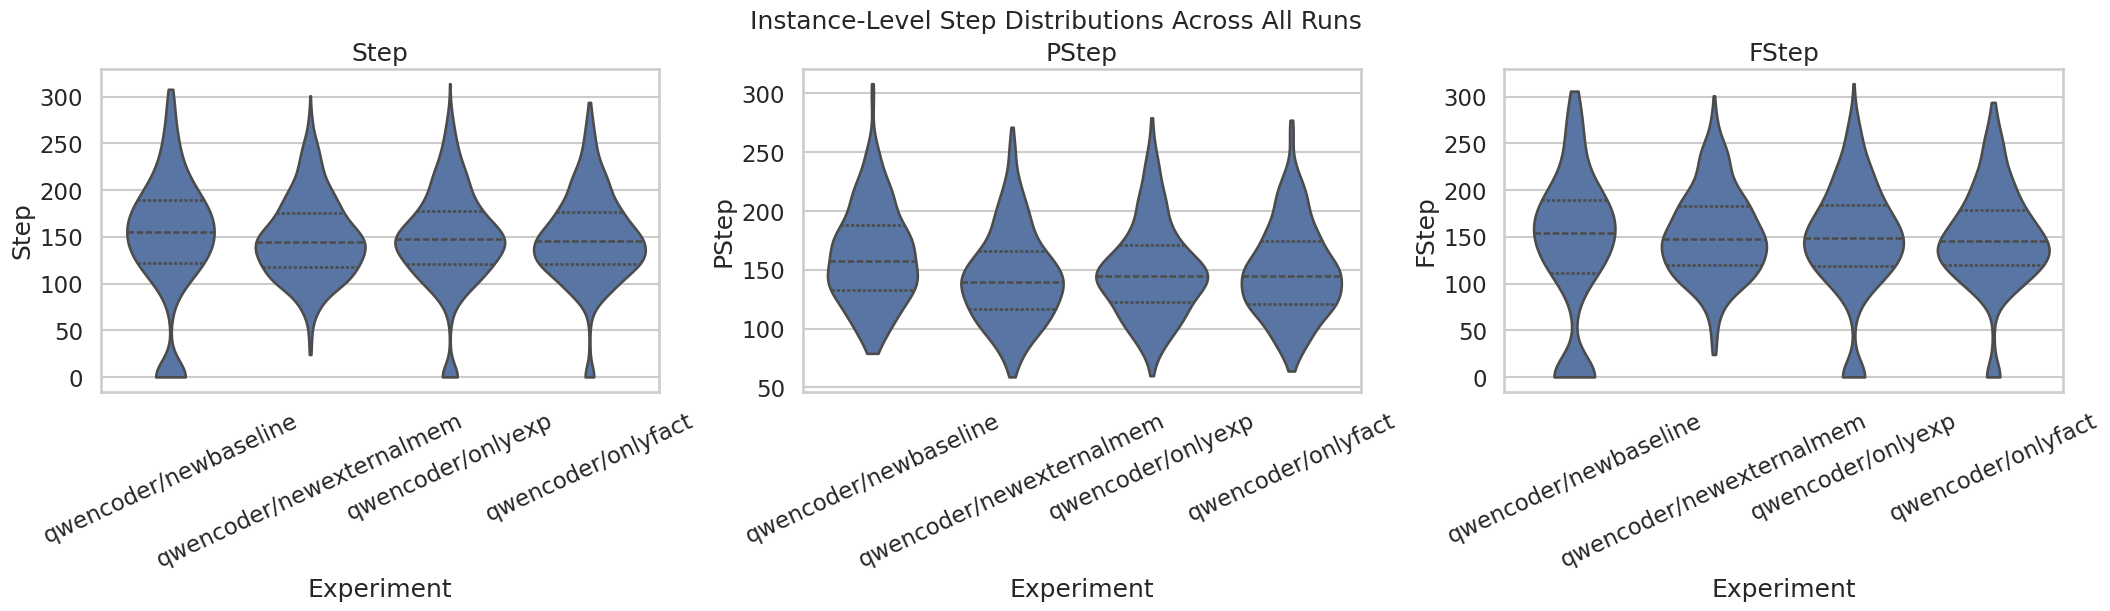

In [6]:
_plot_instance_metric_group(
    instances_df,
    value_column="steps",
    metric_specs=[
        ("Step", instances_df.index == instances_df.index),
        ("PStep", instances_df["passed"]),
        ("FStep", ~instances_df["passed"]),
    ],
    title="Instance-Level Step Distributions Across All Runs",
)


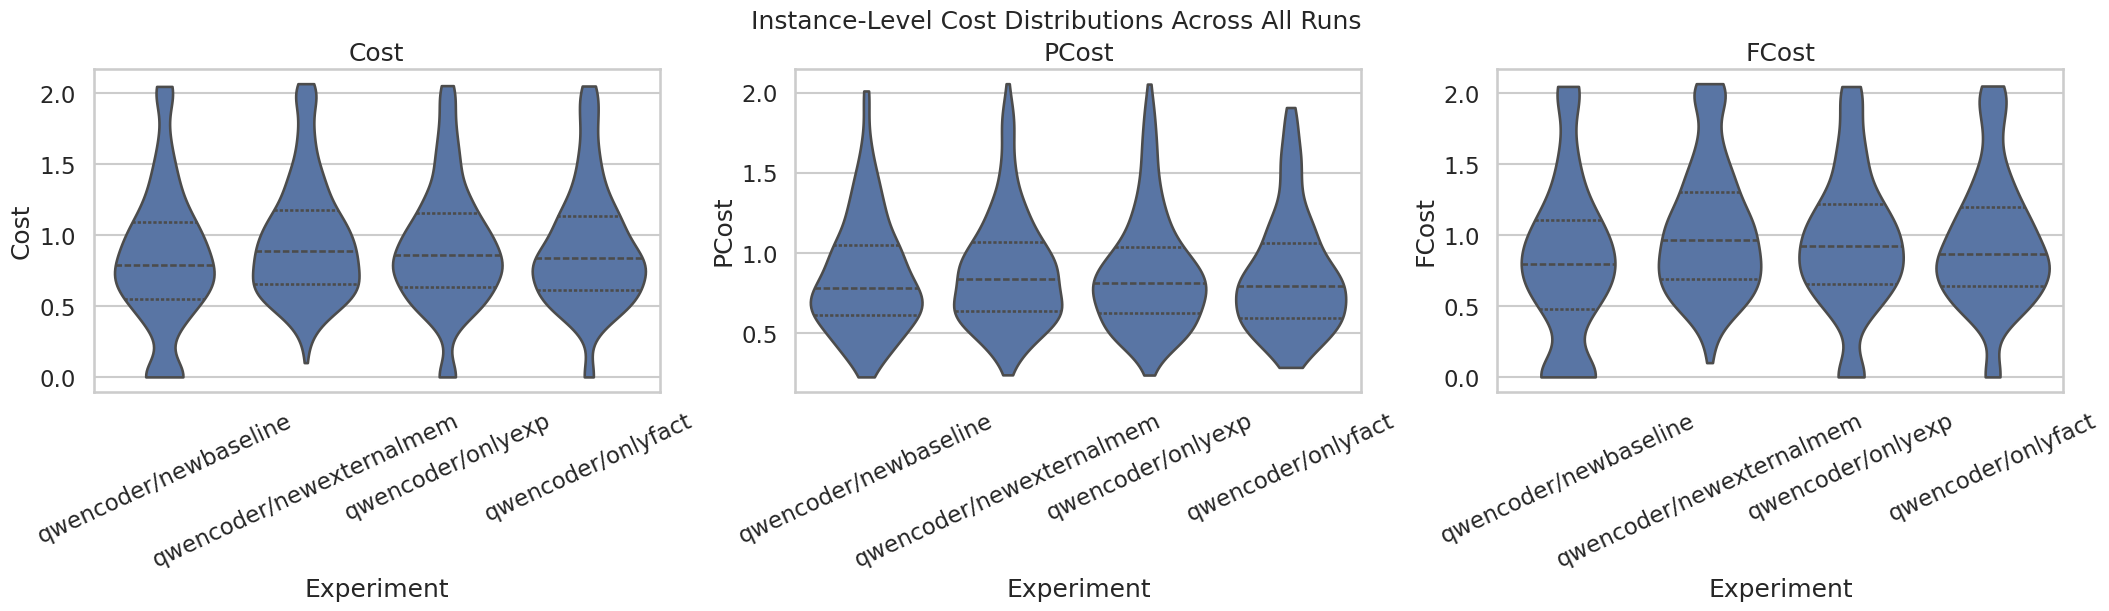

In [7]:
_plot_instance_metric_group(
    instances_df,
    value_column="cost",
    metric_specs=[
        ("Cost", instances_df.index == instances_df.index),
        ("PCost", instances_df["passed"]),
        ("FCost", ~instances_df["passed"]),
    ],
    title="Instance-Level Cost Distributions Across All Runs",
)
